# 02 – Régi hírek: besorolás, H1a és validáció

Ebben a notebookban minden portálcikket új vagy régi hírnek sorolok be Fedyk és Hodson (2023) eljárásával, megbecsülöm a régi hírek arányát (H1a), és a kézi címkékkel megmérem, mennyit téved a besorolás.

**H1a.** A vizsgált időszakban megjelent részvényspecifikus portálcikkek jelentős hányada nem új információt közöl, hanem korábbi dokumentumok (BÉT-közlemények vagy korábbi cikkek) átvétele vagy újrakombinálása.

**Bemenet:** a `korpusz.sqlite` adatbázis `dokumentum`, `hivatkozas` és `beagyazas` táblája, valamint a kézi címkéket tartalmazó `h1a_validacio.xlsx`.

**Kimenet:** `adat/cache/regi_hir.parquet` (cikk×ticker páronként az algoritmus osztálya, ezt olvassa a 03. és a 04. notebook) és, ha még nem létezik, a kézi címkézés munkafüzete.

| szakasz | tartalom |
|---|---|
| 0 | beállítások |
| 1 | szótő-halmazok |
| 2 | a besorolási algoritmus |
| 3 | a besorolás eredménye |
| 4 | érzékenységvizsgálat |
| 5 | mentés |
| 6 | H1a: a régi hírek aránya |
| 7 | a besorolás validációja |

## 0. Beállítások

In [2]:
import os
import re
import sys
import json
import math
import sqlite3
from pathlib import Path
from datetime import datetime
from collections import Counter, defaultdict
from bisect import bisect_left

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import snowballstemmer
from scipy.stats import rankdata
from IPython.display import display

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

PROJEKT = Path(r"C:\Users\User\Desktop\BGE Szakdolgozat")
DB = PROJEKT / "adat" / "korpusz.sqlite"
CACHE = Path(os.environ.get("CACHE_MAPPA", PROJEKT / "adat" / "cache"))
VALIDACIOS_FAJL = CACHE / "h1a_validacio.xlsx"

sys.path.insert(0, str(PROJEKT))
import közös as KÖ
import konfiguracio as K


def db_kapcsolat():
    con = sqlite3.connect(f"file:{DB.as_posix()}?mode=ro", uri=True)
    con.row_factory = sqlite3.Row
    return con

| paraméter | jelentése | értéke |
|---|---|---|
| `REGI_ABLAK_ORA` | ennyi órán belül megjelent korábbi dokumentumokkal vetem össze a cikket | 72 |
| `REGI_SZOMSZED_DB` | a legtöbb közös szótővel rendelkező korábbi dokumentumok száma | 5 |
| `REGI_KUSZOB` | az Old küszöbe: ettől kezdve régi hír a cikk | 0,60 |
| `REGI_ATVETEL_KUSZOB` | a ClosestNeighbor/Old küszöbe: efölött átvétel, alatta újrakombinálás | 0,80 |
| `REGI_MIN_SZO` | ennél kevesebb szótőből álló cikket nem sorolok be | 10 |
| `N_MINTA` | a kézi minta elemszáma | 400 |
| `SEED` | a véletlenszám-generátor magja | 42 |
| `BOOTSTRAP` | a bootstrap ismétléseinek száma | 5 000 |

In [3]:
REGI_ABLAK_ORA = 72
REGI_SZOMSZED_DB = 5
REGI_KUSZOB = 0.60
REGI_ATVETEL_KUSZOB = 0.80
REGI_MIN_SZO = 10
N_MINTA = 400
SEED = 42
BOOTSTRAP = 5000

## 1. Szótő-halmazok
A cikkeket a szókészletük átfedésével hasonlítom össze, ezért a ragozott alakokat közös alapra kell hozni: a magyarban a *részvény*, *részvényt*, *részvényeket* ugyanazt jelenti.

A cím, a lead és a törzs szövegét kisbetűsítem, szavakra bontom, elhagyom a stopszavakat, a többit a Snowball-algoritmus magyar szótövezőjével alapalakra hozom. A számokat és a négy cég nevét változatlanul megtartom, mert egy tranzakció darabszáma vagy ára azonosítja a hírt. A BÉT-közleményeknél a fejlécet, a csatolmánylistát és az elérhetőségeket a `közös.bet_szoveg_tisztit` törli. Egy dokumentumhoz minden olyan tickert hozzárendelek, amely a címben vagy a leadben (`ticker_eros`), illetve csak a törzsszövegben (`ticker_gyenge`) szerepel.

In [4]:
TOKEN = re.compile(r"[^\W_]+")
TOVEZO = snowballstemmer.stemmer("hungarian")
TOVEK = {}
CEGNEVEK = frozenset(["telekom", "richter", "otp", "mol"])
STOPSZAVAK = frozenset("""a az egy és hogy is nem de van volt lesz lett már még meg el ki be fel le át
ez ezt ezek az azt azok ami amely amelyek amit aki mint vagy ha csak által szerint után előtt
között alatt felé során illetve valamint ezzel azzal ebben abban erre arra ide oda itt ott
így úgy miatt ellen óta is sem se mert mivel ezért azért pedig viszont azonban tehát
én te ő mi ti ők őket nekik neki nekem vele rá rá ról ről től tól hoz hez höz nak nek ban ben
ra re ba be val vel ért ig kor""".split())

def szotovek(szoveg):
    halmaz = set()
    for t in TOKEN.findall((szoveg or "").lower()):
        if t in STOPSZAVAK:
            continue
        if t.isdigit():
            halmaz.add(t)
            continue
        if len(t) < 2:
            continue
        if t in CEGNEVEK:
            halmaz.add(t)
            continue
        if t not in TOVEK:
            TOVEK[t] = TOVEZO.stemWord(t)
        halmaz.add(TOVEK[t])
    return frozenset(halmaz)


print(sorted(szotovek("A Magyar Telekom 2024-ben 150 forintos osztalékot fizet a részvényeseknek.")))

['150', '2024', 'fiz', 'forintos', 'magyar', 'osztale', 'részvényes', 'telekom']


In [6]:
def idobelyeg(iso):
    return datetime.fromisoformat(iso.replace("Z", "+00:00")).timestamp()


class Dok:
    def __init__(self, sor):
        self.doc_id = sor["doc_id"]
        self.forras = sor["forras"]
        self.ts = idobelyeg(sor["megjelenes_utc"])
        self.kulcs = (self.ts, 0 if self.forras == "bet" else 1, self.doc_id)
        torzs = KÖ.bet_szoveg_tisztit(sor["szoveg"]) if self.forras == "bet" else (sor["szoveg"] or "")
        self.szavak = szotovek(f"{sor['cim'] or ''} {sor['lead'] or ''} {torzs}")
        self.tickerek_eros = sorted(set(json.loads(sor["ticker_eros"] or "[]")))
        gyenge = set(json.loads(sor["ticker_gyenge"] or "[]"))
        self.tickerek = sorted(set(self.tickerek_eros) | gyenge)


con = db_kapcsolat()
dokok = {}
for sor in con.execute("""SELECT doc_id, forras, cim, lead, szoveg, megjelenes_utc, ticker_eros, ticker_gyenge
                          FROM dokumentum WHERE megjelenes_utc IS NOT NULL AND szoveg IS NOT NULL"""):
    d = Dok(sor)
    dokok[d.doc_id] = d
meta = pd.read_sql("SELECT doc_id, forras, cim, lead, url, megjelenes_helyi FROM dokumentum", con).set_index("doc_id")
forras_link = defaultdict(list)
for sor in con.execute("SELECT doc_id, cel_doc_id FROM hivatkozas WHERE tipus = 'forras' AND cel_doc_id IS NOT NULL"):
    forras_link[sor["doc_id"]].append(sor["cel_doc_id"])
con.close()

print(f"{len(dokok)} dokumentum:", dict(Counter(d.forras for d in dokok.values())))
print(f"{len(TOVEK)} különböző szóalak, {len(forras_link)} cikk hivatkozik egy a korpuszban jelen lévő dokumentumra")

4030 dokumentum: {'bet': 1345, 'portfolio': 2366, 'telex': 319}
122955 különböző szóalak, 373 cikk hivatkozik egy a korpuszban jelen lévő dokumentumra


## 2. A besorolási algoritmus

**Fedyk és Hodson (2023) mértékeit veszik alapul.** Egy cikk annyira régi, amennyire a szókészletét lefedik az ugyanarról a cégről korábban megjelent dokumentumok. Azért ezt az eljárást használom, mert két dolgot választ szét: a cikk tartalma ismert-e már (Old), és ha igen, egyetlen forrásból jön-e (átvétel) vagy több forrás összerakása (újrakombinálás).

*A probléma megoldás pusztán lexikai megközelítésű.* Az $i$ cikk jelöltjei az ugyanahhoz a tickerhez tartozó, a megelőző 72 órában megjelent dokumentumok. Ezek közül a legtöbb közös szótővel rendelkező öt marad meg ($j_1,\dots,j_5$). Ha $W_i$ az $i$ cikk szótő-halmaza:

$$\mathrm{Old}_i=\frac{\left|W_i\cap\bigcup_{k=1}^{5}W_{j_k}\right|}{|W_i|},\qquad \mathrm{Closest}_i=\frac{|W_i\cap W_{j_1}|}{|W_i|}$$

| osztály | feltétel |
|---|---|
| új | $\mathrm{Old}_i<0{,}60$ |
| átvétel | $\mathrm{Old}_i\ge0{,}60$ és $\mathrm{Closest}_i/\mathrm{Old}_i>0{,}80$ |
| újrakombinálás | $\mathrm{Old}_i\ge0{,}60$ és $\mathrm{Closest}_i/\mathrm{Old}_i\le0{,}80$ |

Az eljárást három ponton igazítottam az adatokhoz:

1. A BÉT-közlemény mindig új hír, mert szabályozott elsődleges közlés; más cikkeknek viszont lehet jelöltje. Azonos időpontnál a BÉT-közlemény számít korábbinak.
2. Ha a cikk forrásként linkel egy nála korábbi dokumentumot, a szerkesztőség maga jelölte meg az előzményt. Ez erősebb bizonyíték a szövegegyezésnél, ezért ha a szövegszabály újnak minősítené, a cikk régi hír lesz: egy hivatkozott forrásnál átvétel, többnél újrakombinálás. Az `osztaly_szoveg` oszlop a csak szövegből számolt osztályt őrzi.
3. A 10 szótőnél rövidebb cikket nem sorolom be (`rovid`).

In [7]:
def meres(s, jeloltek):
    pontok = []
    for c in jeloltek:
        kozos = len(s.szavak & c.szavak)
        if kozos > 0:
            pontok.append((kozos, c.kulcs, c))
    pontok.sort(key=lambda p: (p[0], p[1]), reverse=True)
    pontok = pontok[:REGI_SZOMSZED_DB]
    if not pontok:
        return 0.0, 0.0, []
    unio = set()
    for _, _, c in pontok:
        unio.update(s.szavak & c.szavak)
    return len(unio) / len(s.szavak), pontok[0][0] / len(s.szavak), [c for _, _, c in pontok]


def osztaly_dont(old, kozeli, kuszob=REGI_KUSZOB, atvetel_kuszob=REGI_ATVETEL_KUSZOB):
    if old < kuszob:
        return "uj"
    if kozeli / old > atvetel_kuszob:
        return "atvetel"
    return "ujrakombinalt"


def ticker_listak(dokok, ticker_mezo="tickerek"):
    listak = defaultdict(list)
    for d in dokok.values():
        for t in getattr(d, ticker_mezo):
            listak[t].append(d)
    for lista in listak.values():
        lista.sort(key=lambda d: d.kulcs)
    return listak


def jeloltek_valasztas(lista, idok, i, ablak_ora=REGI_ABLAK_ORA):
    s = lista[i]
    kezdet = bisect_left(idok, s.ts - ablak_ora * 3600)
    return [c for c in lista[kezdet:i] if c.kulcs < s.kulcs]

In [22]:
def hivatkozott_korabbiak(s):
    return [c_id for c_id in forras_link.get(s.doc_id, []) if c_id in dokok and dokok[c_id].kulcs < s.kulcs]


def osztalyoz(ticker_mezo="tickerek", ablak_ora=REGI_ABLAK_ORA):
    sorok = []
    for ticker, lista in ticker_listak(dokok, ticker_mezo).items():
        idok = [d.ts for d in lista]
        for i, s in enumerate(lista):
            sor = {"doc_id": s.doc_id, "ticker": ticker, "forras": s.forras, "szoveg_db": len(s.szavak),
                   "hivatkozott": "[]", "szomszedok": "[]", "regi_arany": np.nan, "kozeli_arany": np.nan,
                   "jelolt_db": 0, "bet_elozmeny": False}
            if s.forras == "bet":
                sorok.append({**sor, "osztaly": "uj", "osztaly_szoveg": "uj", "indok": "bet"})
                continue
            jeloltek = jeloltek_valasztas(lista, idok, i, ablak_ora)
            sor["jelolt_db"] = len(jeloltek)
            sor["bet_elozmeny"] = any(c.forras == "bet" for c in jeloltek)
            if len(s.szavak) < REGI_MIN_SZO:
                sorok.append({**sor, "osztaly": "rovid", "osztaly_szoveg": "rovid", "indok": "szoveg"})
                continue
            old, kozeli, szomszedok = meres(s, jeloltek)
            szoveg_osztaly = osztaly_dont(old, kozeli)
            osztaly, indok = szoveg_osztaly, "szoveg"
            korabbiak = hivatkozott_korabbiak(s)
            if korabbiak:
                if szoveg_osztaly == "uj":
                    osztaly = "atvetel" if len(korabbiak) == 1 else "ujrakombinalt"
                    indok = "hivatkozas"
                else:
                    indok = "szoveg+hivatkozas"
            sorok.append({**sor, "regi_arany": old, "kozeli_arany": kozeli, "hivatkozott": json.dumps(korabbiak),
                          "szomszedok": json.dumps([c.doc_id for c in szomszedok]),
                          "osztaly": osztaly, "osztaly_szoveg": szoveg_osztaly, "indok": indok})
    return pd.DataFrame(sorok)


regi = osztalyoz()
print(f"{len(regi)} cikk×ticker pár")

7706 cikk×ticker pár


## 3. A besorolás eredménye

Az elemzés egysége a cikk×ticker pár, mert egy cikk több cégről is szólhat, és cégenként más lehet az előzménye.

In [23]:
display(pd.crosstab(regi.forras, regi.osztaly, margins=True, margins_name="összesen"))
portal = regi[regi.forras != "bet"]
print("A portálos párok besorolásának indoka:", dict(Counter(portal.indok)))
print(f"A hivatkozás-szabály a portálos párok {(portal.osztaly != portal.osztaly_szoveg).mean():.1%}-ánál "
      f"változtatta meg a szöveges osztályt.")

osztaly,atvetel,uj,ujrakombinalt,összesen
forras,,,,
bet,0,1345,0,1345
portfolio,2583,1446,2072,6101
telex,62,171,27,260
összesen,2645,2962,2099,7706


A portálos párok besorolásának indoka: {'szoveg': 5675, 'szoveg+hivatkozas': 284, 'hivatkozas': 402}
A hivatkozás-szabály a portálos párok 6.3%-ánál változtatta meg a szöveges osztályt.


A cikk x ticker párok ábrázolása

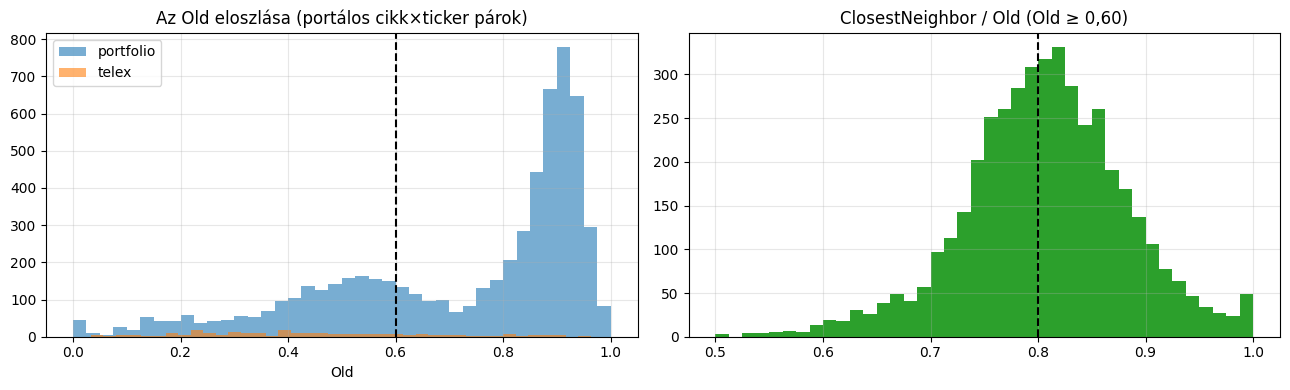

In [8]:
x = portal.dropna(subset=["regi_arany"])
regiek = x[x.regi_arany >= REGI_KUSZOB]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for forras, g in x.groupby("forras"):
    ax[0].hist(g.regi_arany, bins=40, alpha=0.6, label=forras)
ax[0].axvline(REGI_KUSZOB, color="k", ls="--")
ax[0].set_title("Az Old eloszlása (portálos cikk×ticker párok)")
ax[0].set_xlabel("Old")
ax[0].legend()
ax[1].hist(regiek.kozeli_arany / regiek.regi_arany, bins=40, color="C2")
ax[1].axvline(REGI_ATVETEL_KUSZOB, color="k", ls="--")
ax[1].set_title("ClosestNeighbor / Old (Old ≥ 0,60)")
plt.tight_layout()
plt.show()

**Eredmény.** A 7 706 cikk×ticker párból 1 345 BÉT-közlemény (mind új) és 6 361 portálos pár. A portálos párok 74,6%-a (4 744) régi hír az algoritmus szerint: 2 645 átvétel és 2 099 újrakombinálás. A Portfolio odaláról szűrt hírek 76,3%-a, a Telex-ről 34,2%-a régi. A besorolást 5 675 esetben a szöveg döntötte el, 402-nél a hivatkozás-szabály változtatta régire, 284-nél a szöveg és a hivatkozás is régit jelzett; a hivatkozás-szabály összesen a párok 6,3%-ánál módosította a szöveges osztályt. A portálos párok Old-értékének mediánja 0,83. A ClosestNeighbor/Old arány eloszlásának csúcsa 0,81–0,83 között van, a mediánja 0,81, tehát a 0,80-as átvétel-küszöb az eloszlás közepén húzódik, nem egy természetes határon.

## 4. Érzékenységvizsgálat

**Paraméterrács.** Az ablak hosszát és a két küszöböt Fedyk és Hodson angol nyelvű Bloomberg-hírekre állította be, magyar portálcikkekre nem tekinthetők adottnak. Ezért megnézem, mennyire függ a régi hírek aránya a választásuktól.

*A módszer lényege:* a 24, 72 és 168 órás ablakot, öt Old-küszöböt (0,4; 0,5; 0,6; 0,7; 0,75) és három átvétel-küszöböt (0,7; 0,8; 0,9) kombinálom, ez 45 változat. Az Old és a ClosestNeighbor csak az ablaktól függ, ezért ablakonként egyszer számolom ki, és a küszöböket utólag alkalmazom (a hivatkozás-szabállyal együtt). Az arányokat ugyanazon a nevezőn számolom, mint a H1a-t: a besorolt portálos cikk×ticker párokon.

In [24]:
def kuszob_szerint(tabla, kuszob, atvetel_kuszob):
    szoveg = np.where(tabla.regi_arany < kuszob, "uj",
                      np.where(tabla.kozeli_arany / tabla.regi_arany > atvetel_kuszob, "atvetel", "ujrakombinalt"))
    hivatkozas_db = tabla.hivatkozott.map(lambda h: len(json.loads(h))).to_numpy()
    return np.where((szoveg == "uj") & (hivatkozas_db == 1), "atvetel",
                    np.where((szoveg == "uj") & (hivatkozas_db > 1), "ujrakombinalt", szoveg))


racs = []
for ablak in [24, 72, 168]:
    tabla = osztalyoz(ablak_ora=ablak)
    tabla = tabla[(tabla.forras != "bet") & (tabla.osztaly != "rovid")]
    for kuszob in [0.4, 0.5, 0.6, 0.7, 0.75]:
        for atvetel_kuszob in [0.7, 0.8, 0.9]:
            osztaly = pd.Series(kuszob_szerint(tabla, kuszob, atvetel_kuszob))
            racs.append({"ablak (óra)": ablak, "Old-küszöb": kuszob, "átvétel-küszöb": atvetel_kuszob,
                         "N": len(tabla), "régi %": 100 * osztaly.isin(["atvetel", "ujrakombinalt"]).mean(),
                         "átvétel %": 100 * (osztaly == "atvetel").mean(),
                         "újrakombinált %": 100 * (osztaly == "ujrakombinalt").mean()})
racs = pd.DataFrame(racs)
print("A régi hírek aránya (%) az ablak és az Old-küszöb szerint (az átvétel-küszöb ezt nem befolyásolja):")
display(racs.pivot_table(index="ablak (óra)", columns="Old-küszöb", values="régi %").round(1))

A régi hírek aránya (%) az ablak és az Old-küszöb szerint (az átvétel-küszöb ezt nem befolyásolja):


Old-küszöb,0.40,0.50,0.60,0.70,0.75
ablak (óra),,,,,
24,72.8,67.0,61.3,55.1,51.3
72,89.2,82.6,74.6,68.5,66.4
168,97.5,93.8,86.8,75.5,72.5


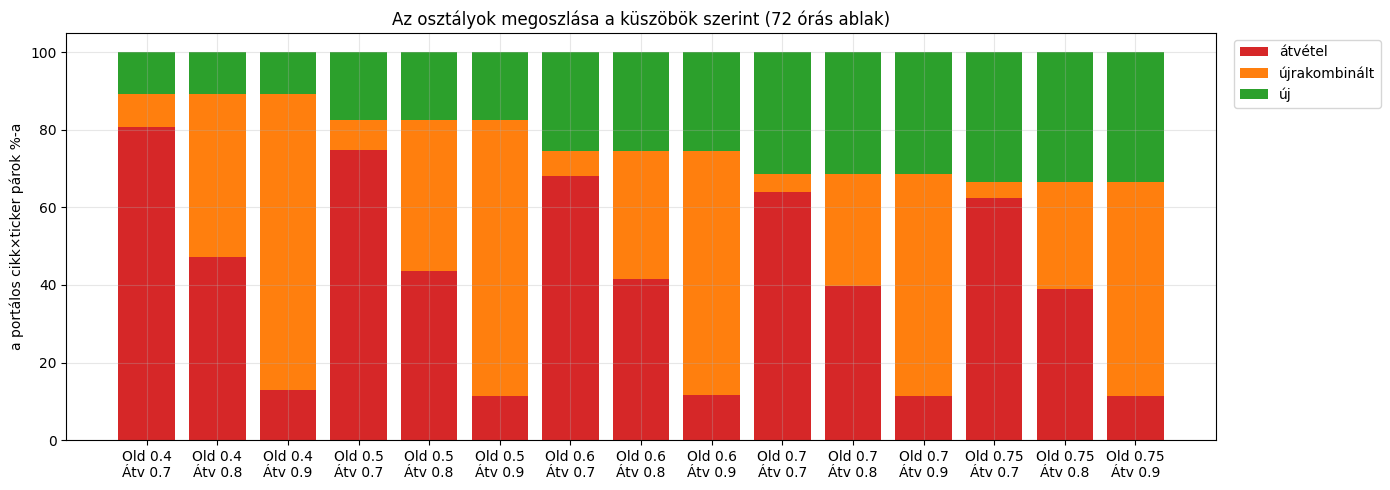

In [25]:
abra = racs[racs["ablak (óra)"] == REGI_ABLAK_ORA].sort_values(["Old-küszöb", "átvétel-küszöb"])
cimkek = [f"Old {o}\nÁtv {a}" for o, a in zip(abra["Old-küszöb"], abra["átvétel-küszöb"])]
fig, ax = plt.subplots(figsize=(14, 5))
alap = np.zeros(len(abra))
for oszlop, szin in [("átvétel %", "C3"), ("újrakombinált %", "C1")]:
    ax.bar(range(len(abra)), abra[oszlop], bottom=alap, color=szin, label=oszlop.replace(" %", ""))
    alap += abra[oszlop].to_numpy()
ax.bar(range(len(abra)), 100 - alap, bottom=alap, color="C2", label="új")
ax.set_xticks(range(len(abra)))
ax.set_xticklabels(cimkek)
ax.set_ylabel("a portálos cikk×ticker párok %-a")
ax.set_title(f"Az osztályok megoszlása a küszöbök szerint ({REGI_ABLAK_ORA} órás ablak)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**Csak erős ticker-kapcsolat.** A vizsgálatban szereplő portálok gyakran közölnek több céget felsoroló piaci összefoglalót, sőt olyan cikkeket amelyekben ömlesztve több papírról is található adat, nagy részük egy céget csak a törzsszövegben említ. Ha ezek a gyenge kapcsolatok torzítanák az arányt, a csak erős kapcsolatú párokon más arányt kapnék.

*A módszer lényege:* a besorolást újra lefuttatom úgy, hogy egy dokumentumhoz csak a címében vagy a leadjében szereplő tickerek tartoznak (`ticker_eros`). Ez a vizsgált cikkekre és a jelöltekre is vonatkozik.

In [26]:
eros = osztalyoz(ticker_mezo="tickerek_eros")
eros_portal = eros[(eros.forras != "bet") & (eros.osztaly != "rovid")]
osszes_portal = regi[(regi.forras != "bet") & (regi.osztaly != "rovid")]
display(pd.DataFrame({
    "N (portálos pár)": [len(osszes_portal), len(eros_portal)],
    "régi %": [100 * osszes_portal.osztaly.isin(["atvetel", "ujrakombinalt"]).mean(),
               100 * eros_portal.osztaly.isin(["atvetel", "ujrakombinalt"]).mean()],
}, index=["erős és gyenge kapcsolat (fő)", "csak erős kapcsolat"]).round(1))

,N (portálos pár),régi %
erős és gyenge kapcsolat (fő),6361,74.6
csak erős kapcsolat,1808,50.5


**Eredmény.** A régi hírek aránya erősen függ a paraméterektől. A 72 órás ablaknál 0,4-es Old-küszöbbel 89,2%, 0,75-össel 66,4%. A legszigorúbb beállításban (24 óra, 0,75) 51,3%, a legengedékenyebben (168 óra, 0,4) 97,5%. Az átvétel-küszöb csak az átvétel és az újrakombinálás arányát változtatja, a régi hírekét nem. Ha csak az erős ticker-kapcsolatot használom, 1 808 portálos pár marad, ezek 50,5%-a régi az algoritmus szerint; a gyenge kapcsolatú, több céget felsoroló cikkek tehát növelik az algoritmus régi-arányát.

## 5. Mentés

A `regi_hir.parquet` az alapparaméterekkel (72 óra, 0,60, 0,80; erős és gyenge kapcsolat) készült besorolást tartalmazza cikk×ticker páronként.

In [28]:
regi.to_parquet(CACHE / "regi_hir.parquet", index=False)
print("Elmentve: regi_hir.parquet")

Elmentve: regi_hir.parquet


## 6. H1a: a régi hírek aránya

### 6.1 A nevező

A nevező a vizsgált időszakban megjelent összes részvényspecifikus portálos eseménypár, vagyis a Portfolio és a Telex besorolt cikk×ticker párjai. A BÉT-közleményeket nem számítom bele, mert definíció szerint új hírek. Kiegészítő bontásként külön közlöm az arányt azokra a portálos párokra, amelyek megjelenését a 72 órás ablakban már megelőzte ugyanarról a cégről egy BÉT-közlemény.

**A bizonytalanság forrása.** Az adatgyűjtés a kétéves időszak teljes állományát lefedi, ezért az algoritmus szerinti régi arány ($p_{\text{alg}}$) a teljes állományon kiszámolható, és nincs mintavételi hibája. A becslés bizonytalansága a besorolás hibájából ered: az algoritmus egyes cikkeket tévesen sorol réginek vagy újnak. Ezért a kézi mintán mért tévesztéssel korrigálom az arányt.

In [30]:
alapsokasag = regi[(regi.forras != "bet") & (regi.osztaly != "rovid")].copy()
alapsokasag["regi_alg"] = alapsokasag.osztaly.isin(["atvetel", "ujrakombinalt"]).astype(int)
N_h = alapsokasag.groupby("forras").size()
p_alg = alapsokasag.regi_alg.mean()
print("A nevező (portálos cikk×ticker párok):", N_h.to_dict(), "összesen:", N_h.sum())
print(f"Az algoritmus szerinti régi arány a teljes állományon: p_alg = {p_alg:.3f}")
print("Rétegenként:", alapsokasag.groupby("forras").regi_alg.mean().round(3).to_dict())
bet_utan = alapsokasag[alapsokasag.bet_elozmeny]
print(f"BÉT-közleményt követő párok: {len(bet_utan)} ({len(bet_utan) / len(alapsokasag):.1%}), "
      f"ezek közül az algoritmus szerint régi: {bet_utan.regi_alg.mean():.3f}")

A nevező (portálos cikk×ticker párok): {'portfolio': 6101, 'telex': 260} összesen: 6361
Az algoritmus szerinti régi arány a teljes állományon: p_alg = 0.746
Rétegenként: {'portfolio': 0.763, 'telex': 0.342}
BÉT-közleményt követő párok: 3546 (55.7%), ezek közül az algoritmus szerint régi: 0.779


### 6.2 A kézi minta

**Rétegzett véletlen minta.** A besorolás hibáját csak úgy tudom megmérni, ha egy véletlenszerűen kiválasztott részt kézzel is megcímkézek. A két portál cikkei eltérő jellegűek, ezért a mintát portálonként (rétegenként) húzom, hogy mindkettő a súlyának megfelelően szerepeljen.

*A módszer lényege:* a 400 elemű mintát a rétegek méretével arányosan osztom el, és rétegenként visszatevés nélkül, egyszerű véletlen mintavétellel választom ki. A mintavételi arány minden rétegben azonos, ezért a minta egyszerű átlaga a teljes állomány becslése.

**Kézi címkézés.** A kódoló a minta minden eleméhez megkapja az ugyanarról a cégről a megelőző 72 órában megjelent összes dokumentumot url-lel, nem csak az algoritmus öt szomszédját, így a választását nem befolyásolja az algoritmus. Az algoritmus besorolása nincs a munkafüzetben. A munkafüzetet a cella csak akkor írja meg, ha még nem létezik, hogy a kitöltött címkék ne vesszenek el. A címkézés szabályait a dolgozat melléklete tartalmazza.

In [31]:
def mintat_vesz(pop, n_osszes, seed):
    n_h = (n_osszes * pop.groupby("forras").size() / len(pop)).round().astype(int)
    return pd.concat([pop[pop.forras == f].sample(n=n_h[f], replace=False, random_state=seed) for f in n_h.index])


minta = mintat_vesz(alapsokasag, N_MINTA, SEED).reset_index(drop=True)
minta["minta_id"] = minta.index + 1
print(f"A minta mérete: {len(minta)}, rétegenként:", minta.groupby("forras").size().to_dict())
print(f"Mintavételi arány rétegenként:", (minta.groupby("forras").size() / N_h).round(4).to_dict())

A minta mérete: 400, rétegenként: {'portfolio': 384, 'telex': 16}
Mintavételi arány rétegenként: {'portfolio': 0.0629, 'telex': 0.0615}


In [32]:
LISTAK = ticker_listak(dokok)
IDOK = {t: [d.ts for d in lista] for t, lista in LISTAK.items()}
HELY = {(d.doc_id, t): i for t, lista in LISTAK.items() for i, d in enumerate(lista)}


def ablak_cikkek(doc_id, ticker):
    return jeloltek_valasztas(LISTAK[ticker], IDOK[ticker], HELY[(doc_id, ticker)])


def munkafuzet_irasa():
    from openpyxl.cell.cell import ILLEGAL_CHARACTERS_RE

    def tiszta(ertek):
        return ILLEGAL_CHARACTERS_RE.sub("", ertek) if isinstance(ertek, str) else ertek

    sor_minta, sor_ablak = [], []
    for r in minta.itertuples():
        sor_minta.append({"minta_id": r.minta_id, "doc_id": r.doc_id, "ticker": r.ticker, "forras": r.forras,
                          "megjelenes_helyi": meta.megjelenes_helyi[r.doc_id], "cim": meta.cim[r.doc_id],
                          "lead": str(meta.lead[r.doc_id] or "")[:250], "url": meta.url[r.doc_id],
                          "ablak_db": r.jelolt_db, "kezi_regi": None, "kezi_forras_url": None, "megjegyzes": None})
        for c in sorted(ablak_cikkek(r.doc_id, r.ticker), key=lambda c: c.kulcs, reverse=True):
            sor_ablak.append({"minta_id": r.minta_id, "ticker": r.ticker, "jelolt_forras": c.forras,
                              "jelolt_megjelenes_helyi": meta.megjelenes_helyi[c.doc_id],
                              "ora_elteres": round((dokok[r.doc_id].ts - c.ts) / 3600, 1),
                              "jelolt_cim": meta.cim[c.doc_id], "jelolt_lead": str(meta.lead[c.doc_id] or "")[:250],
                              "jelolt_url": meta.url[c.doc_id]})
    with pd.ExcelWriter(VALIDACIOS_FAJL, engine="openpyxl") as iro:
        for nev, lap in {"minta": pd.DataFrame(sor_minta), "ablak": pd.DataFrame(sor_ablak)}.items():
            lap.map(tiszta).to_excel(iro, sheet_name=nev, index=False)


if VALIDACIOS_FAJL.exists():
    print("A munkafüzet már létezik, nem írom felül:", VALIDACIOS_FAJL.name)
else:
    munkafuzet_irasa()
    print("Létrehozva:", VALIDACIOS_FAJL.name)

A munkafüzet már létezik, nem írom felül: h1a_validacio.xlsx


### 6.3 A kézi címkék beolvasása

A cella ellenőrzi, hogy minden mintaelemnek van címkéje (1: régi, 0: új), hogy a munkafüzet ehhez a mintához tartozik, és hogy a régi címkéknél megadott forrás-url szerepel-e a mintaelem ablakában.

In [33]:
kezi = pd.read_excel(VALIDACIOS_FAJL, sheet_name="minta")
ablak_lap = pd.read_excel(VALIDACIOS_FAJL, sheet_name="ablak")
if kezi.kezi_regi.isna().any() or not kezi.kezi_regi.isin([0, 1]).all():
    raise ValueError("A kezi_regi oszlopban minden sorban 0 vagy 1 kell")
minta = minta.merge(kezi[["minta_id", "doc_id", "ticker", "kezi_regi", "kezi_forras_url"]],
                    on=["minta_id", "doc_id", "ticker"], how="inner")
if len(minta) != N_MINTA:
    raise ValueError("A munkafüzet nem ehhez a mintához tartozik")
minta["kezi_regi"] = minta.kezi_regi.astype(int)


def url_lista(ertek):
    return [u.strip() for u in str(ertek).replace("\n", ";").split(";") if u.strip() and u.strip() != "nan"]


ervenyes = set(zip(ablak_lap.minta_id, ablak_lap.jelolt_url))
regi_cimkek = minta[minta.kezi_regi == 1]
rendben = sum(len(url_lista(r.kezi_forras_url)) > 0 and all((r.minta_id, u) in ervenyes for u in url_lista(r.kezi_forras_url))
              for r in regi_cimkek.itertuples())
print(f"Kézi címkék: {len(minta)}, ebből régi: {len(regi_cimkek)}")
print(f"Régi címkék, amelyeknél a forrás-url megvan és az ablakban szerepel: {rendben} / {len(regi_cimkek)}")

Kézi címkék: 400, ebből régi: 236
Régi címkék, amelyeknél a forrás-url megvan és az ablakban szerepel: 228 / 236


### 6.4 A tévesztési mátrix: pontosság (precision) és felidézés (recall)

**Tévesztési mátrix.** A kézi címkét tekintem helyesnek, és megszámolom, hányszor egyezik vele az algoritmus. Ebből két arány kell a korrekcióhoz.

*A módszer lényege:*

| | kézi: régi | kézi: új |
|---|---|---|
| algoritmus: régi | TP | FP |
| algoritmus: új | FN | TN |

- **Pontosság (precision)** $=\frac{TP}{TP+FP}$: az algoritmus által réginek jelölt párok közül hány valóban régi.
- **Felidézés (recall)** $=\frac{TP}{TP+FN}$: a valóban régi párok közül hányat talál meg az algoritmus.

In [34]:
def tevesztes(algo, kezi_cimke):
    algo = np.asarray(algo)
    kezi_cimke = np.asarray(kezi_cimke)
    return {"TP": int(((algo == 1) & (kezi_cimke == 1)).sum()), "FP": int(((algo == 1) & (kezi_cimke == 0)).sum()),
            "FN": int(((algo == 0) & (kezi_cimke == 1)).sum()), "TN": int(((algo == 0) & (kezi_cimke == 0)).sum())}


m = tevesztes(minta.regi_alg, minta.kezi_regi)
display(pd.DataFrame([[m["TP"], m["FP"]], [m["FN"], m["TN"]]],
                     index=["algoritmus: régi", "algoritmus: új"], columns=["kézi: régi", "kézi: új"]))
pontossag = m["TP"] / (m["TP"] + m["FP"])
felidezes = m["TP"] / (m["TP"] + m["FN"])
print(f"Pontosság (precision): {pontossag:.3f}")
print(f"Felidézés (recall):    {felidezes:.3f}")
print(f"Az algoritmus a mintában {minta.regi_alg.mean():.1%}-ot, a kézi címke {minta.kezi_regi.mean():.1%}-ot jelöl réginek.")

,kézi: régi,kézi: új
algoritmus: régi,197,108
algoritmus: új,39,56


Pontosság (precision): 0.646
Felidézés (recall):    0.835
Az algoritmus a mintában 76.2%-ot, a kézi címke 59.0%-ot jelöl réginek.


### 6.5 A tévesztéssel korrigált arány

**Korrekció a pontossággal és a felidézéssel.** Az algoritmus a teljes állományon $p_{\text{alg}}$ arányt jelöl réginek, de ezek egy része valójában új, és a valóban régiek egy részét nem találja meg. A két hibát a kézi mintán mért két aránnyal javítom.

*A módszer lényege:* az algoritmus által réginek jelölt $N\,p_{\text{alg}}$ párból a pontosság szerinti hányad valóban régi ($N\,p_{\text{alg}}\cdot\text{precision}$). Ez a valóban régi párok felidézésnyi része, ezért az összes valóban régi pár száma ennek a felidézéssel osztott értéke. A korrigált arány:

$$\hat p=p_{\text{alg}}\cdot\frac{\text{precision}}{\text{recall}}$$

**Klaszter-bootstrap a konfidenciaintervallumhoz.** A $p_{\text{alg}}$ a teljes állományon mért érték, ezért a bizonytalanság csak a kézi mintán becsült precisionből és recallból jön. Egy cikk több tickerhez is tartozhat, és ugyanannak a cikknek a párjai nem függetlenek egymástól, ezért a cikket (`doc_id`) kezelem klaszterként.

*A módszer lényege:* portálonként (rétegenként) visszatevéssel újrahúzom a mintába került cikkeket, mindegyiket az összes párjával együtt, és minden húzásban újraszámolom a precisiont, a recallt és a $\hat p$-t. 5 000 ismétlés 2,5. és 97,5. percentilise adja a 95%-os konfidenciaintervallumot. Összehasonlításul a kézi címkék közvetlen arányát is közlöm ugyanezzel az intervallummal.

In [35]:
def klaszter_bootstrap(adat, statisztika, ismetles=BOOTSTRAP, seed=SEED):
    rng = np.random.default_rng(seed)
    sorok = defaultdict(list)
    for i, doc_id in enumerate(adat.doc_id.to_numpy()):
        sorok[doc_id].append(i)
    retegek = adat.groupby("forras").doc_id.unique()
    eredmeny = []
    for _ in range(ismetles):
        idx = []
        for docok in retegek:
            for doc_id in rng.choice(docok, size=len(docok), replace=True):
                idx.extend(sorok[doc_id])
        eredmeny.append(statisztika(np.array(idx)))
    return np.array(eredmeny, dtype=float)


def korrigalt_arany(algo, kezi_cimke, p):
    tp = ((algo == 1) & (kezi_cimke == 1)).sum()
    if (algo == 1).sum() == 0 or (kezi_cimke == 1).sum() == 0:
        return np.nan
    return p * (tp / (algo == 1).sum()) / (tp / (kezi_cimke == 1).sum())


def h1a_becsles(adat, p):
    algo = adat.regi_alg.to_numpy()
    kezi_cimke = adat.kezi_regi.to_numpy()
    pont = korrigalt_arany(algo, kezi_cimke, p)
    ci = np.nanpercentile(klaszter_bootstrap(adat, lambda idx: korrigalt_arany(algo[idx], kezi_cimke[idx], p)), [2.5, 97.5])
    kozvetlen_ci = np.percentile(klaszter_bootstrap(adat, lambda idx: kezi_cimke[idx].mean()), [2.5, 97.5])
    return pont, ci, kezi_cimke.mean(), kozvetlen_ci


pont, ci, kozvetlen, kozvetlen_ci = h1a_becsles(minta, p_alg)
minta_bet = minta[minta.bet_elozmeny]
pont_b, ci_b, kozvetlen_b, kozvetlen_ci_b = h1a_becsles(minta_bet, bet_utan.regi_alg.mean())

h1a_tabla = pd.DataFrame([
    {"becslés": "az algoritmus aránya (p_alg)", "nevező": "összes portálos pár", "N vagy n": len(alapsokasag),
     "régi %": 100 * p_alg, "CI alsó": np.nan, "CI felső": np.nan},
    {"becslés": "precision/recall-korrigált (fő)", "nevező": "összes portálos pár", "N vagy n": len(minta),
     "régi %": 100 * pont, "CI alsó": 100 * ci[0], "CI felső": 100 * ci[1]},
    {"becslés": "kézi címkék közvetlen aránya", "nevező": "összes portálos pár", "N vagy n": len(minta),
     "régi %": 100 * kozvetlen, "CI alsó": 100 * kozvetlen_ci[0], "CI felső": 100 * kozvetlen_ci[1]},
    {"becslés": "az algoritmus aránya (p_alg)", "nevező": "BÉT-közleményt követő pár", "N vagy n": len(bet_utan),
     "régi %": 100 * bet_utan.regi_alg.mean(), "CI alsó": np.nan, "CI felső": np.nan},
    {"becslés": "precision/recall-korrigált", "nevező": "BÉT-közleményt követő pár", "N vagy n": len(minta_bet),
     "régi %": 100 * pont_b, "CI alsó": 100 * ci_b[0], "CI felső": 100 * ci_b[1]},
    {"becslés": "kézi címkék közvetlen aránya", "nevező": "BÉT-közleményt követő pár", "N vagy n": len(minta_bet),
     "régi %": 100 * kozvetlen_b, "CI alsó": 100 * kozvetlen_ci_b[0], "CI felső": 100 * kozvetlen_ci_b[1]},
])
display(h1a_tabla.round(1))
print("Pontosság és felidézés a BÉT-közleményt követő mintaelemeken:",
      {k: round(v, 3) for k, v in zip(["precision", "recall"],
       [minta_bet[minta_bet.regi_alg == 1].kezi_regi.mean(), minta_bet[minta_bet.kezi_regi == 1].regi_alg.mean()])})

,becslés,nevező,N vagy n,régi %,CI alsó,CI felső
0,az algoritmus aránya (p_alg),összes portálos pár,6361,74.6,NaN,NaN
1,precision/recall-korrigált (fő),összes portálos pár,400,57.7,52.8,62.9
2,kézi címkék közvetlen aránya,összes portálos pár,400,59.0,54.1,63.9
3,az algoritmus aránya (p_alg),BÉT-közleményt követő pár,3546,77.9,NaN,NaN
4,precision/recall-korrigált,BÉT-közleményt követő pár,228,58.5,52.1,65.3
5,kézi címkék közvetlen aránya,BÉT-közleményt követő pár,228,61.0,54.6,67.4


Pontosság és felidézés a BÉT-közleményt követő mintaelemeken: {'precision': np.float64(0.649), 'recall': np.float64(0.863)}


**Eredmény.** A nevező 6 361 portálos cikk×ticker pár (Portfolio 6 101, Telex 260). Az algoritmus ezek 74,6%-át jelöli réginek. A kézi mintán a pontosság 0,646 (az algoritmus 305 régi jelöléséből 197 valóban régi), a felidézés 0,835 (a 236 valóban régi párból 197-et talál meg). A precision/recall-korrigált régi arány 57,7% (95%-os CI: 52,8–62,9%), a kézi címkék közvetlen aránya ezzel egybevág (59,0%; 54,1–63,9%). Az algoritmus tehát kb. 17 százalékponttal túlbecsüli a régi hírek arányát. A portálos párok 55,7%-át (3 546) előzte meg 72 órán belül BÉT-közlemény ugyanarról a cégről; ezeknél az algoritmus aránya 77,9%, a korrigált arány 58,5% (52,1–65,3%, a mintából 228 elem). A portálcikkek jelentős hányada, a becslés szerint 53–63%-a régi hír.

## 7. A besorolás validációja

A 03. és a 04. notebook az algoritmus címkéit használja, ezért a besorolás hibái a H1b és a kutatási kérdés eredményére is átöröklődnek. Ebben a szakaszban azt mérem, mennyire egyezik az algoritmus a kézi címkével, és hogy egy másik szöveges mérték jobban szétválasztaná-e a régi és az új híreket. Minden konfidenciaintervallum a 6.5 szakasz cikkszintű klaszter-bootstrapjével készül.

### 7.1 Egyezés és Cohen-kappa

**Cohen-kappa.** Az egyszerű egyezési arány félrevezető, ha az egyik címke gyakori: ha az algoritmus mindent réginek jelölne, a minta régi arányával egyezne a kézi címkével. A kappa ezt a véletlen egyezést kiveszi (Cohen, 1960).

*A módszer lényege:* $\kappa=\frac{p_o-p_e}{1-p_e}$, ahol $p_o$ a megfigyelt egyezés, $p_e$ a két címkézés gyakoriságából várható véletlen egyezés. A 0 azt jelenti, hogy az egyezés nem jobb a véletlennél, az 1 a teljes egyezést; 0,2 alatt az egyezés gyenge (Landis & Koch, 1977). Mellette a szenzitivitást (a recallt) és a specificitást (a kézzel újnak jelölt párok közül hányat jelöl újnak az algoritmus) is közlöm. Cikk×ticker páronként és egyedi cikkenként is számolok; cikkszinten egy cikk régi, ha valamelyik párja régi.

In [36]:
def egyezes_mutatok(algo, kezi_cimke):
    t = tevesztes(algo, kezi_cimke)
    n = sum(t.values())
    p_o = (t["TP"] + t["TN"]) / n
    p_e = ((t["TP"] + t["FP"]) * (t["TP"] + t["FN"]) + (t["TN"] + t["FN"]) * (t["TN"] + t["FP"])) / n ** 2
    return {"n": n, "egyezés": p_o, "kappa": (p_o - p_e) / (1 - p_e) if p_e < 1 else np.nan,
            "szenzitivitás": t["TP"] / (t["TP"] + t["FN"]), "specificitás": t["TN"] / (t["TN"] + t["FP"])}


cikkek = minta.groupby(["doc_id", "forras"], as_index=False).agg(regi_alg=("regi_alg", "max"), kezi_regi=("kezi_regi", "max"))
sorok = []
for nev, adat in [("cikk×ticker pár", minta), ("egyedi cikk", cikkek)]:
    algo, kezi_cimke = adat.regi_alg.to_numpy(), adat.kezi_regi.to_numpy()
    e = egyezes_mutatok(algo, kezi_cimke)
    ci = np.nanpercentile(klaszter_bootstrap(adat, lambda idx: egyezes_mutatok(algo[idx], kezi_cimke[idx])["kappa"]), [2.5, 97.5])
    sorok.append({"szint": nev, **e, "kappa CI": f"[{ci[0]:.2f}; {ci[1]:.2f}]"})
display(pd.DataFrame(sorok).set_index("szint").round(3))

,n,egyezés,kappa,szenzitivitás,specificitás,kappa CI
szint,,,,,,
cikk×ticker pár,400,0.632,0.188,0.835,0.341,[0.10; 0.28]
egyedi cikk,373,0.633,0.180,0.834,0.333,[0.08; 0.27]


### 7.2 A küszöb és a cikk jellemzői

**Küszöbtábla.** Ha a gyenge egyezést rosszul megválasztott küszöb okozná, egy másik Old-küszöbnél nagyobb kappát kapnék. Itt a hivatkozás-szabály nélküli, csak szövegből számolt Old-ot használom.

**Alcsoportok.** A rövid cikkek szókincsét a korábbi cikkek könnyebben lefedik, ezért megnézem, hogyan függ az algoritmus és a kézi címke régi aránya a cikk hosszától (egyedi szótövek száma), a portáltól és attól, hogy a cikk hivatkozik-e korábbi dokumentumra.

In [37]:
x = minta.dropna(subset=["regi_arany"])
sorok = []
for k in [0.4, 0.5, 0.6, 0.7, 0.75, 0.8, 0.9]:
    tipp = (x.regi_arany >= k).astype(int)
    e = egyezes_mutatok(tipp, x.kezi_regi)
    sorok.append({"Old-küszöb": k, "algoritmus régi %": 100 * tipp.mean(), "egyezés": e["egyezés"], "kappa": e["kappa"]})
display(pd.DataFrame(sorok).set_index("Old-küszöb").round(3))

csoport = minta.assign(
    hossz=pd.cut(minta.szoveg_db, bins=[0, 100, 300, np.inf], labels=["<=100 szótő", "101-300 szótő", ">300 szótő"]),
    hivatkozas=np.where(minta.hivatkozott == "[]", "nincs", "van"),
    egyezik=(minta.regi_alg == minta.kezi_regi).astype(int))
for oszlop in ["hossz", "forras", "hivatkozas"]:
    tabla = csoport.groupby(oszlop, observed=True).agg(
        n=("kezi_regi", "size"), algoritmus_regi=("regi_alg", "mean"), kezi_regi=("kezi_regi", "mean"), egyezes=("egyezik", "mean"))
    tabla[["algoritmus_regi", "kezi_regi", "egyezes"]] *= 100
    display(tabla.round(1))

,algoritmus régi %,egyezés,kappa
Old-küszöb,,,
0.40,88.50,0.610,0.094
0.50,78.25,0.592,0.093
0.60,69.50,0.585,0.107
0.70,61.50,0.560,0.082
0.75,59.50,0.555,0.078
0.80,55.25,0.532,0.047
0.90,32.00,0.480,0.023


,n,algoritmus_regi,kezi_regi,egyezes
hossz,,,,
<=100 szótő,253,94.5,60.9,63.2
101-300 szótő,38,65.8,39.5,63.2
>300 szótő,109,37.6,61.5,63.3


,n,algoritmus_regi,kezi_regi,egyezes
forras,,,,
portfolio,384,78.1,59.4,63.0
telex,16,31.2,50.0,68.8


,n,algoritmus_regi,kezi_regi,egyezes
hivatkozas,,,,
nincs,352,73.0,55.4,60.2
van,48,100.0,85.4,85.4


### 7.3 Más átfedésmérők szétválasztó ereje (AUC)

**AUC.** A küszöbtől független kérdés az, hogy egy mérték egyáltalán szétválasztja-e a kézzel régi és új cikkeket. Az AUC annak a valószínűsége, hogy egy véletlenül választott régi cikk mértéke nagyobb egy véletlenül választott új cikkénél: 0,5 a véletlen, 1 a tökéletes szétválasztás.

*A módszer lényege:* az AUC a mértékek rangjaiból számolható ki, az egyező értékek fél pontot kapnak. A kipróbált mértékek:

| mérték | mit mér |
|---|---|
| Old | az alapalgoritmus mértéke |
| IDF-súlyozott Old | mint az Old, de a szótövek súlya $\ln\big(N/(1+df_w)\big)$, így a sok dokumentumban előforduló általános szavak (árfolyam, részvény, forint) keveset számítanak; az öt szomszédot is a súlyozott átfedés alapján választom |
| szám/tulajdonnév-fedés | a cikk számainak és mondat közbeni nagybetűs szavainak (IDF-súlyozott) hányada, amely az ablak valamelyik korábbi dokumentumában is szerepel; a cég saját nevét kihagyom |
| csak számok fedése | ugyanez csak a számokra |
| új szavak száma | a cikk le nem fedett szótöveinek száma, $|W_i|(1-\mathrm{Old}_i)$, ellentett előjellel; ez nem függ a cikk hosszának arányától |
| tartalmazás | az ablak legalább 20 szótőből álló dokumentumai közül annak a szótő-halmazából mekkora hányadot tartalmaz a cikk, amelyikből a legtöbbet |

In [40]:
def auc(pontszam, kezi_cimke):
    pontszam = np.asarray(pontszam, dtype=float)
    kezi_cimke = np.asarray(kezi_cimke)
    n_regi, n_uj = (kezi_cimke == 1).sum(), (kezi_cimke == 0).sum()
    if n_regi == 0 or n_uj == 0:
        return np.nan
    return (rankdata(pontszam)[kezi_cimke == 1].sum() - n_regi * (n_regi + 1) / 2) / (n_regi * n_uj)


def suly_osszeg(szavak, sulyok):
    return sum(sulyok.get(w, 0.0) for w in szavak)


df_szo = Counter()
for d in dokok.values():
    df_szo.update(d.szavak)
idf = {w: max(0.0, math.log(len(dokok) / (1 + db))) for w, db in df_szo.items()}


def old_idf(s, jeloltek):
    nevezo = suly_osszeg(s.szavak, idf)
    pontok = sorted(((suly_osszeg(s.szavak & c.szavak, idf), c.kulcs, s.szavak & c.szavak) for c in jeloltek if s.szavak & c.szavak),
                    key=lambda p: (p[0], p[1]), reverse=True)[:REGI_SZOMSZED_DB]
    unio = set().union(*[p[2] for p in pontok]) if pontok else set()
    return suly_osszeg(unio, idf) / nevezo if nevezo > 0 else np.nan


SZAM = re.compile(r"\d{1,3}(?:[ \u00a0]\d{3})+(?:,\d+)?|\d+(?:[.,]\d+)?")
SZO = re.compile(r"[^\W\d_]+|[.!?]")
SAJAT_NEVEK = CEGNEVEK | frozenset(["magyar", "gedeon", "nyrt", "bank", "budapesti"])


def kulcs_tokenek(cim, lead, torzs):
    szoveg = f"{cim or ''}. {lead or ''}. {torzs or ''}"
    szamok = {"#" + t for t in (m.group(0).replace(" ", "").replace("\u00a0", "").replace(",", ".") for m in SZAM.finditer(szoveg)) if len(t) >= 2}
    nevek, mondat_eleje = set(), True
    for w in SZO.findall(szoveg):
        if w in ".!?":
            mondat_eleje = True
            continue
        if w[0].isupper() and not mondat_eleje and len(w) >= 3 and w.lower() not in SAJAT_NEVEK:
            nevek.add("@" + TOVEZO.stemWord(w.lower()))
        mondat_eleje = False
    return frozenset(szamok), frozenset(nevek)


szukseges = set(minta.doc_id) | {c.doc_id for r in minta.itertuples() for c in ablak_cikkek(r.doc_id, r.ticker)}
con = db_kapcsolat()
kulcsok = {}
for sor in con.execute(f"SELECT doc_id, forras, cim, lead, szoveg FROM dokumentum WHERE doc_id IN ({','.join('?' * len(szukseges))})", list(szukseges)):
    torzs = KÖ.bet_szoveg_tisztit(sor["szoveg"]) if sor["forras"] == "bet" else sor["szoveg"]
    kulcsok[sor["doc_id"]] = kulcs_tokenek(sor["cim"], sor["lead"], torzs)
con.close()
kulcs_df = Counter()
for szamok, nevek in kulcsok.values():
    kulcs_df.update(szamok | nevek)
kulcs_idf = {t: max(0.0, math.log(len(kulcsok) / (1 + db))) for t, db in kulcs_df.items()}


def kulcs_fedes(doc_id, ticker, csak_szam):
    szamok, nevek = kulcsok[doc_id]
    sajat = szamok if csak_szam else szamok | nevek
    elozmeny = set()
    for c in ablak_cikkek(doc_id, ticker):
        cs, cn = kulcsok[c.doc_id]
        elozmeny |= cs if csak_szam else cs | cn
    nevezo = suly_osszeg(sajat, kulcs_idf)
    return suly_osszeg(sajat & elozmeny, kulcs_idf) / nevezo if nevezo > 0 else np.nan


def tartalmazas(doc_id, ticker, min_szo=20):
    s = dokok[doc_id].szavak
    return max([len(s & c.szavak) / len(c.szavak) for c in ablak_cikkek(doc_id, ticker) if len(c.szavak) >= min_szo], default=0.0)

merok = pd.DataFrame({
    "Old": minta.regi_arany,
    "IDF-súlyozott Old": [old_idf(dokok[r.doc_id], ablak_cikkek(r.doc_id, r.ticker)) for r in minta.itertuples()],
    "szám/tulajdonnév-fedés": [kulcs_fedes(r.doc_id, r.ticker, False) for r in minta.itertuples()],
    "csak számok fedése": [kulcs_fedes(r.doc_id, r.ticker, True) for r in minta.itertuples()],
    "új szavak száma": -minta.szoveg_db * (1 - minta.regi_arany),
    "tartalmazás": [tartalmazas(r.doc_id, r.ticker) for r in minta.itertuples()],
})

sorok = []
for nev in merok.columns:
    van = merok[nev].notna().to_numpy()
    adat = minta[van].reset_index(drop=True)
    p, k = merok[nev][van].to_numpy(), adat.kezi_regi.to_numpy()
    ci = np.nanpercentile(klaszter_bootstrap(adat, lambda idx: auc(p[idx], k[idx])), [2.5, 97.5])
    sorok.append({"mérték": nev, "n": len(adat), "AUC": auc(p, k), "CI alsó": ci[0], "CI felső": ci[1]})
auc_tabla = pd.DataFrame(sorok).set_index("mérték").round(3)
display(auc_tabla)

,n,AUC,CI alsó,CI felső
mérték,,,,
Old,400,0.540,0.479,0.597
IDF-súlyozott Old,400,0.540,0.479,0.598
szám/tulajdonnév-fedés,400,0.571,0.514,0.627
csak számok fedése,399,0.583,0.526,0.638
új szavak száma,400,0.518,0.461,0.576
tartalmazás,400,0.525,0.466,0.585


### 7.4 Mennyit vesz át a cikk a kézzel megjelölt forrásból?

A kódoló a régi címkéknél megadta a forrás url-jét. Ha a régi hírek szó szerinti átvételek volnának, a cikk a forrás szótöveinek nagy részét tartalmazná. Ezt a megadott források közül a legtöbbet tartalmazott forrással mérem.

In [41]:
url_doc = {url: doc_id for doc_id, url in meta.url.items()}
ertekek = []
for r in minta[minta.kezi_regi == 1].itertuples():
    s = dokok[r.doc_id].szavak
    forrasok = [dokok[url_doc[u]].szavak for u in url_lista(r.kezi_forras_url) if url_doc.get(u) in dokok]
    forrasok = [f for f in forrasok if len(f) > 0]
    if forrasok:
        ertekek.append(max(len(s & f) / len(f) for f in forrasok))
ertekek = pd.Series(ertekek)
print(f"Számolható régi címkék: {len(ertekek)}")
print(f"A forrás szótöveinek átlagosan {ertekek.mean():.1%}-át tartalmazza a cikk (medián {ertekek.median():.1%})")
print(f"A forrás legalább 80%-át tartalmazza: {(ertekek >= 0.8).mean():.1%}")

Számolható régi címkék: 229
A forrás szótöveinek átlagosan 52.0%-át tartalmazza a cikk (medián 60.3%)
A forrás legalább 80%-át tartalmazza: 2.6%


### 7.5 Téves kizárás a teljes kézi mintán

**Téves kizárás.** Ha egy szűrő a régi hírnek jelölt cikkeket kizárja, a kizártak egy része valójában új hír. Ennek aránya a téves kizárás, $h=1-\text{precision}$. A 04. notebook ugyanezt a nyitvatartásban megjelent jelekre számolja, itt a teljes mintára adom meg.

*A módszer lényege:* a szöveges szabály az algoritmus szerint régi párokat zárja ki, a hivatkozásos szabály a korábbi korpuszbeli dokumentumra hivatkozó párokat. Az összehasonlítási alap a véletlen kizárás, amelynél a kizártak régi hányada a minta régi aránya. A teljes állományra vetítve a szöveges szabály által kizárt párok közül $N\,p_{\text{alg}}\cdot\text{precision}$ lehet valóban régi.

In [42]:
def kizaras(adat, kizart, nev):
    kizart = np.asarray(kizart, dtype=bool)
    k = adat.kezi_regi.to_numpy()
    h = 1 - k[kizart].mean()
    ci = np.nanpercentile(klaszter_bootstrap(adat, lambda idx: 1 - k[idx][kizart[idx]].mean() if kizart[idx].any() else np.nan), [2.5, 97.5])
    return {"szabály": nev, "kizárt": int(kizart.sum()), "kizárt %": 100 * kizart.mean(), "pontosság %": 100 * (1 - h),
            "téves kizárás %": 100 * h, "CI alsó": 100 * ci[0], "CI felső": 100 * ci[1]}


display(pd.DataFrame([kizaras(minta, minta.regi_alg == 1, "szöveges"),
                      kizaras(minta, minta.hivatkozott != "[]", "hivatkozásos")]).set_index("szabály").round(1))
print(f"Véletlen kizárás pontossága (a minta régi aránya): {minta.kezi_regi.mean():.1%}")
kizart_db = int(alapsokasag.regi_alg.sum())
print(f"A teljes állományon a szöveges szabály {kizart_db} párt zárna ki, ebből a becslés szerint "
      f"{kizart_db * pontossag:.0f} régi és {kizart_db * (1 - pontossag):.0f} új hír.")

,kizárt,kizárt %,pontosság %,téves kizárás %,CI alsó,CI felső
szabály,,,,,,
szöveges,305,76.2,64.6,35.4,30.1,40.9
hivatkozásos,48,12.0,85.4,14.6,5.6,25.5


Véletlen kizárás pontossága (a minta régi aránya): 59.0%
A teljes állományon a szöveges szabály 4744 párt zárna ki, ebből a becslés szerint 3064 régi és 1680 új hír.


**Eredmény.**

- Cikk×ticker páronként az egyezés 63,2%, a Cohen-kappa 0,188 (95%-os CI: 0,10–0,28), a szenzitivitás 83,5%, a specificitás 34,1%. Egyedi cikkeken (n = 373) a kappa 0,180 (0,08–0,27). A kappa a gyenge sávban van: az algoritmus a kézzel újnak jelölt párok kétharmadát is réginek jelöli.
- Az Old-küszöb változtatása nem segít, a kappa 0,02 és 0,11 között marad.
- A hossz erősen torzít: a legfeljebb 100 szótőből álló cikkek 94,5%-át, a 300 szótőnél hosszabbak 37,6%-át jelöli réginek az algoritmus, miközben a kézi arány mindkét csoportban 61% körül van. A hivatkozás megbízható jel, még akkor is ha nem mindig veszi észre a kézi kódoló és a 48 hivatkozó párnál az egyezés 85,4%.
- Egyik átfedésmérő sem választja szét jól a régi és az új híreket. Az Old és az IDF-súlyozott Old AUC-ja egyaránt 0,540, az intervallumuk tartalmazza a 0,5-öt. A szám/tulajdonnév-fedés (0,571; 0,514–0,627) és a csak számok fedése (0,583; 0,526–0,638) valamivel jobb, az intervallum alsó határa 0,5 fölött van. Az új szavak száma (0,518), a tartalmazás (0,525) és a beágyazás (0,553) sem jobb.
- Amit régi hírnek ítéltem, az ritkán szó szerinti másolat: a cikk a kézzel megjelölt forrás szótöveinek átlagosan 52,0%-át tartalmazza, 80%-nál többet csak 2,6%-ban.